**Introducción a la Ciencia de Datos 2026**  
Posgrado en Ciencias de la Computación - CICESE  
Erick Gabriel Santiago Suenaga

# Tarea 5: CNN

En clase se vio que una CNN con Flatten llegó a 96.87 % de exactitud en validación con 54,330 parámetros entrenables, y la misma red con Global Average Pooling (GAP) bajó a 2,650 parámetros pero solo acertó el 44.07 %. El objetivo de esta tarea es encontrar una CNN con GAP que supere el **95 % de exactitud en validación** con **menos de 54,330 parámetros entrenables** y, entre las que lo logren, quedarse con la que tenga menos parámetros. Después se mide qué tan bien reconoce los dígitos de MNIST cuando cambia su posición en la imagen, comparada con las dos redes base.

El notebook tiene tres partes: se recuperan los dos modelos de referencia, se entrenan doce variantes con GAP para elegir una usando solo validación, y al final se comparan los tres modelos en prueba con los dígitos desplazados 0, 2 y 4 píxeles.

---

## Preparación

Se usan TensorFlow/Keras para las redes, NumPy y pandas para las tablas, scikit-learn para las particiones y Matplotlib para las gráficas. Los colores son los de las sesiones anteriores: el naranja se reserva para el GAP seleccionado.

Las constantes son las del notebook de clase: semilla 42, lotes de 128, Adam con tasa de 0.001 y **20 épocas** para todos los modelos. Así cualquier diferencia entre variantes se debe a la arquitectura y no al entrenamiento.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from IPython.display import display
from sklearn.model_selection import train_test_split
from tensorflow import keras

tf.get_logger().setLevel("ERROR")

print("numpy      ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("tensorflow  ", tf.__version__)

numpy       2.5.5
pandas       3.1.1
matplotlib   3.11.2
scikit-learn 1.9.1
tensorflow   2.21.0


In [2]:
AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
AZUL_MEDIO = "#3C51A9"
NARANJA = "#E76A28"
GRIS = "#5B6584"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlecolor": AZUL_OSCURO,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": AZUL_OSCURO,
    "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E3E6EF",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "legend.frameon": False,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)


SEMILLA = 42
N_ENT, N_VAL, N_PRUEBA = 8000, 1500, 2000
MARGEN = 4
CAPAS = (16, 16)
LOTE = 128
EPOCAS = 20
TASA = 0.001

---

### Los datos

MNIST (LeCun *et al.*, 1998) tiene imágenes de dígitos manuscritos de **28 × 28** píxeles en escala de grises, con diez clases del 0 al 9: 60,000 en el conjunto oficial de entrenamiento y 10,000 en el de prueba. Keras lo descarga en la primera ejecución.

Se usan las mismas particiones estratificadas del notebook de clase:

- **Entrenamiento:** 8,000 imágenes del conjunto oficial de entrenamiento.
- **Validación:** 1,500 imágenes del mismo conjunto, distintas de las de entrenamiento. Con ellas se toman todas las decisiones de arquitectura.
- **Prueba:** 2,000 imágenes del conjunto oficial de prueba. Se usan una sola vez, en la comparación final con desplazamientos.

A cada imagen se le agrega un **margen negro de 4 píxeles** por lado, así que la red recibe **36 × 36 × 1**. Ese margen permite mover el dígito hasta 4 píxeles en cualquier dirección sin recortar el trazo.

In [3]:
(x_des, y_des), (x_test, y_test) = keras.datasets.mnist.load_data()
i_ent, i_val = train_test_split(
    np.arange(len(y_des)), train_size=N_ENT, test_size=N_VAL,
    stratify=y_des, random_state=SEMILLA,
)
i_prueba, _ = train_test_split(
    np.arange(len(y_test)), train_size=N_PRUEBA, stratify=y_test,
    random_state=SEMILLA,
)


def preparar_imagenes(imagenes):
    """Agrega el margen negro de 4 píxeles por lado, el eje del canal y escala a [0, 1]."""
    imagenes = np.pad(imagenes, ((0, 0), (MARGEN, MARGEN), (MARGEN, MARGEN)))
    return imagenes[..., None].astype(np.float32) / 255.0


X_ent, y_ent = preparar_imagenes(x_des[i_ent]), y_des[i_ent]
X_val, y_val = preparar_imagenes(x_des[i_val]), y_des[i_val]
X_prueba, y_prueba = preparar_imagenes(x_test[i_prueba]), y_test[i_prueba]
FORMA = X_ent.shape[1:]

for nombre, X in [("Entrenamiento", X_ent), ("Validación", X_val), ("Prueba", X_prueba)]:
    print(f"{nombre:14s} {X.shape}  min={X.min():.1f}  max={X.max():.1f}")

Entrenamiento  (8000, 36, 36, 1)  min=0.0  max=1.0
Validación     (1500, 36, 36, 1)  min=0.0  max=1.0
Prueba         (2000, 36, 36, 1)  min=0.0  max=1.0


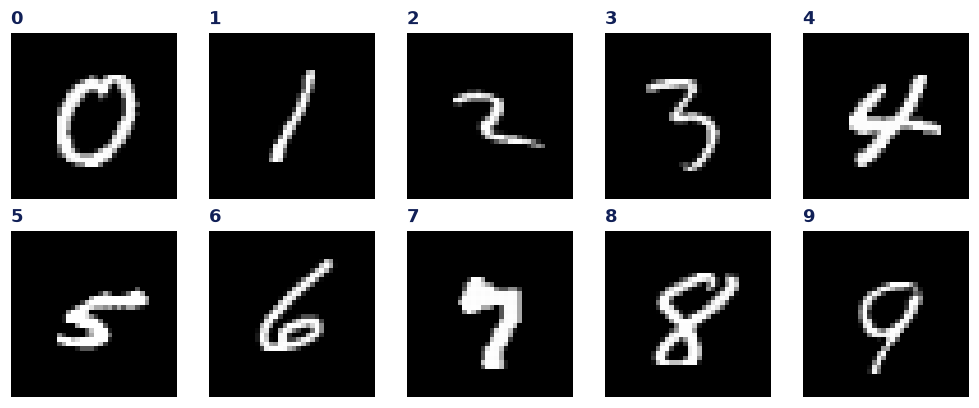

In [4]:
fig, ejes = plt.subplots(2, 5, figsize=(9, 3.6), layout="constrained")
for digito, ax in enumerate(ejes.flat):
    i = np.flatnonzero(y_ent == digito)[0]
    ax.imshow(X_ent[i, ..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(str(digito))
    ax.axis("off")
plt.show()

Las tres particiones tienen la forma `36 × 36 × 1` y valores entre 0 y 1. En los ejemplos se ve el dígito centrado en su marco original de 28 × 28, rodeado por la franja negra de 4 píxeles.

---

## 1. Modelos de referencia

**Pregunta / Punto.** Recupera los modelos de referencia con las mismas particiones de MNIST y el margen negro de cuatro píxeles del notebook.

Las dos redes base comparten el extractor: dos convoluciones de 16 filtros de 3 × 3 con ReLU y `padding="same"`, y un *max pooling* de 2 × 2 al final, que deja mapas de 18 × 18 × 16. Solo cambia cómo llegan esos mapas a la capa de diez clases:

- **Flatten** entrega $18 \cdot 18 \cdot 16 = 5{,}184$ valores, y la capa densa necesita $(5{,}184 + 1) \times 10 = 51{,}850$ pesos.
- **GAP** promedia cada canal sobre todo el mapa y entrega 16 valores, así que la capa densa necesita $(16 + 1) \times 10 = 170$ pesos.

Las funciones `crear_cnn`, `lotes` y `entrenar` son las del notebook de clase, sin cambios. `parametros` suma los pesos entrenables de todo el modelo.

In [5]:
def crear_cnn(filtros=CAPAS, padding="same", pooling="max", stride=1, cabeza="flatten"):
    """CNN del notebook de clase: convoluciones 3 × 3, un pooling al final y cabeza Flatten o GAP."""
    capas = [keras.Input(shape=FORMA)]
    for i, n_filtros in enumerate(filtros):
        capas.append(keras.layers.Conv2D(
            n_filtros, 3, strides=stride if i == 0 else 1,
            padding=padding, activation="relu", name=f"conv_{i + 1}",
        ))
    if pooling == "max":
        capas.append(keras.layers.MaxPooling2D(2, name="pool"))
    elif pooling == "average":
        capas.append(keras.layers.AveragePooling2D(2, name="pool"))
    elif pooling != "sin":
        raise ValueError("pooling debe ser 'max', 'average' o 'sin'")

    if cabeza == "flatten":
        capas.append(keras.layers.Flatten(name="vector"))
    elif cabeza == "gap":
        capas.append(keras.layers.GlobalAveragePooling2D(name="vector"))
    else:
        raise ValueError("cabeza debe ser 'flatten' o 'gap'")

    capas.append(keras.layers.Dense(10, activation="softmax", name="salida"))
    return keras.Sequential(capas, name=f"cnn_{cabeza}")


def lotes(X, y=None, mezclar=False):
    """Dataset por lotes; la mezcla usa la semilla fija."""
    datos = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if mezclar:
        datos = datos.shuffle(len(X), seed=SEMILLA)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 2
    return datos.batch(LOTE).with_options(opciones).prefetch(1)


def entrenar(constructor, **configuracion):
    """Entrena con la semilla, el optimizador, la tasa y las 20 épocas del notebook de clase."""
    keras.utils.set_random_seed(SEMILLA)
    modelo = constructor(**configuracion)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TASA),
        loss="sparse_categorical_crossentropy",
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
    )
    historial = modelo.fit(
        lotes(X_ent, y_ent, mezclar=True),
        validation_data=lotes(X_val, y_val),
        epochs=EPOCAS, verbose=0, shuffle=False,
    ).history
    return modelo, historial


def parametros(modelo):
    """Parámetros entrenables de todo el modelo (kernels y sesgos)."""
    return sum(int(np.prod(v.shape)) for v in modelo.trainable_weights)

In [6]:
modelo_flatten, hist_flatten = entrenar(crear_cnn, cabeza="flatten")
modelo_gap_base, hist_gap_base = entrenar(crear_cnn, cabeza="gap")
PARAMS_FLATTEN = parametros(modelo_flatten)

referencia = pd.DataFrame({
    "Mapas antes del vector": [" × ".join(map(str, m.get_layer("vector").input.shape[1:]))
                               for m in (modelo_flatten, modelo_gap_base)],
    "Longitud del vector": [int(m.get_layer("vector").output.shape[-1])
                            for m in (modelo_flatten, modelo_gap_base)],
    "Parámetros capa densa": [m.get_layer("salida").count_params()
                              for m in (modelo_flatten, modelo_gap_base)],
    "Parámetros entrenables": [PARAMS_FLATTEN, parametros(modelo_gap_base)],
    "Validación (%) · esta ejecución": [100 * hist_flatten["val_accuracy"][-1],
                                        100 * hist_gap_base["val_accuracy"][-1]],
    "Validación (%) · ejecución guardada": [96.87, 44.07],
}, index=pd.Index(["CNN + Flatten", "CNN + GAP base"], name="Modelo"))
referencia.round(2)

,Mapas antes del vector,Longitud del vector,Parámetros capa densa,Parámetros entrenables,Validación (%) · esta ejecución,Validación (%) · ejecución guardada
Modelo,,,,,,
CNN + Flatten,18 × 18 × 16,5184,51850,54330,96.80,96.87
CNN + GAP base,18 × 18 × 16,16,170,2650,43.93,44.07


Los parámetros coinciden exactamente con la ejecución guardada (54,330 y 2,650), y la exactitud de validación difiere en décimas: 96.80 % contra 96.87 % para Flatten y 43.93 % contra 44.07 % para el GAP base. Los datos y la configuración son los mismos, así que la diferencia viene de la versión de TensorFlow y del orden de las operaciones en CPU. En el resto del notebook se usan los modelos de esta ejecución, para que todas las comparaciones salgan de las mismas condiciones.

Casi todos los parámetros de Flatten están en la capa densa: 51,850 de 54,330 (95.4 %). GAP elimina ese costo, pero con este extractor cada neurona del mapa final solo ve un parche de 6 × 6 píxeles. Al promediar el canal, la red sabe cuánto trazo de cierto tipo hay en la imagen, pero no cómo están acomodados los trazos, y eso no alcanza para separar los diez dígitos.

---

## 2. Variantes con GAP

**Pregunta / Punto.** Entrena al menos seis variantes de la CNN con GAP cambiando el número de filtros, la profundidad, el tamaño de los kernels o la ubicación del pooling. Incluye al menos dos comparaciones en las que cambie una sola decisión. Registra la exactitud de validación a las 20 épocas y los parámetros entrenables, y selecciona la variante con menos parámetros entre las que superen 95 %.

### 2.1 Cómo se describen las arquitecturas

Todas las variantes terminan igual: `GlobalAveragePooling2D` y una capa `Dense(10)` con softmax. Lo que cambia es el extractor, que se escribe como una secuencia de bloques:

- **Un número** es una convolución con ese número de filtros, ReLU, `padding="same"` y stride 1. El kernel es de 3 × 3 salvo que el nombre diga `(5 × 5)`.
- **`P`** es un *max pooling* de 2 × 2, que reduce el mapa a la mitad: 36 → 18 → 9 → 4 → 2.

Por ejemplo, `4-P-8-P-16-P-16-P` es conv(4) → pool → conv(8) → pool → conv(16) → pool → conv(16) → pool → GAP → Dense(10).

La tabla incluye el **campo receptivo**: el lado, en píxeles de la entrada, de la región que influye en una sola neurona del último mapa. Cada convolución de 3 × 3 lo amplía en 2 veces el paso acumulado, y cada pooling lo amplía y duplica ese paso. Es útil aquí porque GAP promedia cada canal sobre toda la imagen. Si cada neurona solo ve un trozo de trazo, el promedio solo dice *cuánto* de ese trazo hay, no *qué dígito* forma.

In [7]:
def crear_gap(bloques, kernel=3):
    """CNN con cabeza GAP. Un número es una Conv2D con esos filtros; "P" es un MaxPooling2D(2)."""
    capas = [keras.Input(shape=FORMA)]
    n_conv = n_pool = 0
    for b in bloques:
        if b == "P":
            n_pool += 1
            capas.append(keras.layers.MaxPooling2D(2, name=f"pool_{n_pool}"))
        else:
            n_conv += 1
            capas.append(keras.layers.Conv2D(b, kernel, padding="same", activation="relu",
                                             name=f"conv_{n_conv}"))
    capas.append(keras.layers.GlobalAveragePooling2D(name="vector"))
    capas.append(keras.layers.Dense(10, activation="softmax", name="salida"))
    return keras.Sequential(capas, name="cnn_gap")


def nombre_arquitectura(bloques, kernel=3):
    """[4, "P", 8, "P"] -> "4-P-8-P"; agrega (5 × 5) si el kernel no es 3 × 3."""
    nombre = "-".join(str(b) for b in bloques)
    return nombre if kernel == 3 else f"{nombre} (5 × 5)"


def campo_receptivo(bloques, kernel=3):
    """Lado, en píxeles de la entrada, de la región que ve una neurona del último mapa."""
    campo, salto = 1, 1
    for b in bloques:
        if b == "P":
            campo += salto      # ventana 2 × 2
            salto *= 2          # paso 2
        else:
            campo += (kernel - 1) * salto
    return campo

In [8]:
P = "P"
VARIANTES = {
    # clave: (bloques, kernel, qué cambia respecto a su par)
    "V0": ([16, 16, P], 3, "GAP base del notebook de clase"),
    "V1": ([16, 16, 16, P], 3, "V0 + una convolución, pooling al final"),
    "V2": ([16, P, 16, P, 16, P], 3, "V1 con el pooling intercalado"),
    "V3": ([16, P, 16, P, 16, P, 16, P], 3, "V2 + una etapa conv + pool"),
    "V4": ([4, P, 8, P, 16, P, 16, P], 3, "V3 con filtros 4-8-16-16"),
    "V5": ([4, P, 8, P, 16, P, 16], 3, "V4 sin el último pooling"),
    "V6": ([4, P, 8, P, 16, P, 16, P], 5, "V4 con kernels 5 × 5"),
    "V7": ([4, P, 8, P, 16, P], 3, "V4 sin la cuarta etapa"),
    "V8": ([4, P, 8, P, 16, P, 12, P], 3, "V4 con 12 filtros en la última capa"),
    "V9": ([3, P, 6, P, 12, P, 12, P], 3, "V4 con todas las capas más estrechas"),
    "V10": ([8, P, 8, P, 16, P, 16, P], 3, "V4 con 8 filtros en la primera capa"),
    "V11": ([6, P, 12, P, 24, P, 32, P], 3, "V4 con más filtros en todas las capas"),
}

descripcion = []
for clave, (bloques, kernel, cambio) in VARIANTES.items():
    m = crear_gap(bloques, kernel)
    descripcion.append({
        "Variante": clave,
        "Arquitectura": nombre_arquitectura(bloques, kernel),
        "Qué cambia": cambio,
        "Conv": sum(b != P for b in bloques),
        "Pool": bloques.count(P),
        "Mapa antes de GAP": " × ".join(map(str, m.get_layer("vector").input.shape[1:])),
        "Campo receptivo (px)": campo_receptivo(bloques, kernel),
        "Parámetros entrenables": parametros(m),
    })
descripcion = pd.DataFrame(descripcion).set_index("Variante")
descripcion

,Arquitectura,Qué cambia,Conv,Pool,Mapa antes de GAP,Campo receptivo (px),Parámetros entrenables
Variante,,,,,,,
V0,16-16-P,GAP base del notebook de clase,2,1,18 × 18 × 16,6,2650
V1,16-16-16-P,"V0 + una convolución, pooling al final",3,1,18 × 18 × 16,8,4970
V2,16-P-16-P-16-P,V1 con el pooling intercalado,3,3,4 × 4 × 16,22,4970
V3,16-P-16-P-16-P-16-P,V2 + una etapa conv + pool,4,4,2 × 2 × 16,46,7290
V4,4-P-8-P-16-P-16-P,V3 con filtros 4-8-16-16,4,4,2 × 2 × 16,46,3994
V5,4-P-8-P-16-P-16,V4 sin el último pooling,4,3,4 × 4 × 16,38,3994
V6,4-P-8-P-16-P-16-P (5 × 5),V4 con kernels 5 × 5,4,4,2 × 2 × 16,76,10714
V7,4-P-8-P-16-P,V4 sin la cuarta etapa,3,3,4 × 4 × 16,22,1674
V8,4-P-8-P-16-P-12-P,V4 con 12 filtros en la última capa,4,4,2 × 2 × 12,46,3374


Las doce variantes forman dos familias. De `V0` a `V3` se conservan 16 filtros por capa y solo se agregan convoluciones o se mueve el pooling. De `V5` a `V11` se parte de `V4` y se cambia una cosa a la vez: se quita el último pooling (`V5`), se usan kernels de 5 × 5 (`V6`), se quita la cuarta etapa (`V7`) o se cambia el número de filtros (`V8` a `V11`).

La tabla ya anticipa el efecto del pooling. `V1` y `V2` tienen las mismas tres convoluciones y los mismos 4,970 parámetros, pero el campo receptivo pasa de 8 a 22 píxeles, porque cada pooling duplica el paso con el que avanzan las convoluciones siguientes. Con cuatro etapas de convolución y pooling (`V3`, `V4`), el campo receptivo llega a 46 píxeles y cubre toda la imagen de 36 × 36.

### 2.2 Entrenamiento y tabla de validación

Cada variante se entrena con `entrenar`: misma semilla, mismas particiones, mismo optimizador y las mismas 20 épocas que los modelos base. Se registra la exactitud de validación **al final de la época 20**, no la mejor época, y los parámetros entrenables de todo el modelo. `V0` es exactamente la red del GAP base, así que se reutiliza el modelo ya entrenado.

La columna `Cumple` es verdadera solo si la exactitud es **mayor** que 95 % y los parámetros son menos de 54,330. Flatten aparece en la primera fila como referencia.

In [9]:
modelos_gap, historiales_gap = {}, {}
for clave, (bloques, kernel, _) in VARIANTES.items():
    if clave == "V0":       # misma red que el GAP base: se reutiliza en lugar de entrenarla dos veces
        modelos_gap[clave], historiales_gap[clave] = modelo_gap_base, hist_gap_base
        continue
    modelos_gap[clave], historiales_gap[clave] = entrenar(crear_gap, bloques=bloques, kernel=kernel)

tabla_val = descripcion[["Arquitectura", "Mapa antes de GAP", "Campo receptivo (px)",
                         "Parámetros entrenables"]].copy()
tabla_val["Parámetros entrenables"] = [parametros(modelos_gap[c]) for c in tabla_val.index]
tabla_val["Validación época 20 (%)"] = [100 * historiales_gap[c]["val_accuracy"][-1]
                                        for c in tabla_val.index]
tabla_val["Cumple"] = ((tabla_val["Validación época 20 (%)"] > 95)
                       & (tabla_val["Parámetros entrenables"] < PARAMS_FLATTEN))

fila_flatten = pd.DataFrame({
    "Arquitectura": "16-16-P + Flatten",
    "Mapa antes de GAP": "— (Flatten de 18 × 18 × 16)",
    "Campo receptivo (px)": campo_receptivo([16, 16, P]),
    "Parámetros entrenables": PARAMS_FLATTEN,
    "Validación época 20 (%)": 100 * hist_flatten["val_accuracy"][-1],
    "Cumple": False,
}, index=pd.Index(["Flatten"], name="Variante"))
display(pd.concat([fila_flatten, tabla_val]).round(2))

,Arquitectura,Mapa antes de GAP,Campo receptivo (px),Parámetros entrenables,Validación época 20 (%),Cumple
Variante,,,,,,
Flatten,16-16-P + Flatten,— (Flatten de 18 × 18 × 16),6,54330,96.80,False
V0,16-16-P,18 × 18 × 16,6,2650,43.93,False
V1,16-16-16-P,18 × 18 × 16,8,4970,53.53,False
V2,16-P-16-P-16-P,4 × 4 × 16,22,4970,90.20,False
V3,16-P-16-P-16-P-16-P,2 × 2 × 16,46,7290,95.33,True
V4,4-P-8-P-16-P-16-P,2 × 2 × 16,46,3994,95.60,True
V5,4-P-8-P-16-P-16,4 × 4 × 16,38,3994,92.73,False
V6,4-P-8-P-16-P-16-P (5 × 5),2 × 2 × 16,76,10714,95.60,True
V7,4-P-8-P-16-P,4 × 4 × 16,22,1674,85.13,False


### 2.3 Comparaciones de una sola decisión

Cada fila compara dos variantes que difieren en una sola decisión de diseño. En la ubicación del pooling, `V1` y `V2` tienen exactamente las mismas convoluciones y los mismos parámetros: solo cambia dónde va el pooling, que no tiene pesos. En las demás filas se agrega o se quita una etapa, se cambia el kernel o se cambia el ancho, y el resto de la red queda igual.

In [10]:
COMPARACIONES = [
    # (decisión, variante A, variante B)
    ("Profundidad con pooling al final", "V0", "V1"),
    ("Ubicación del pooling", "V1", "V2"),
    ("Profundidad con pooling intercalado", "V2", "V3"),
    ("Profundidad con pooling intercalado", "V7", "V4"),
    ("Pooling antes de GAP", "V5", "V4"),
    ("Tamaño del kernel", "V4", "V6"),
    ("Filtros en todas las capas", "V3", "V4"),
    ("Filtros en la última capa", "V8", "V4"),
]

filas = []
for decision, a, b in COMPARACIONES:
    acc_a, acc_b = tabla_val.loc[a, "Validación época 20 (%)"], tabla_val.loc[b, "Validación época 20 (%)"]
    par_a, par_b = tabla_val.loc[a, "Parámetros entrenables"], tabla_val.loc[b, "Parámetros entrenables"]
    filas.append({
        "Decisión": decision,
        "A": f"{a} · {tabla_val.loc[a, 'Arquitectura']}",
        "B": f"{b} · {tabla_val.loc[b, 'Arquitectura']}",
        "Parámetros A → B": f"{par_a:,} → {par_b:,}",
        "Validación A (%)": acc_a,
        "Validación B (%)": acc_b,
        "Cambio (pp)": acc_b - acc_a,
    })
pd.DataFrame(filas).round(2)

,Decisión,A,B,Parámetros A → B,Validación A (%),Validación B (%),Cambio (pp)
0,Profundidad con pooling al final,V0 · 16-16-P,V1 · 16-16-16-P,"2,650 → 4,970",43.93,53.53,9.60
1,Ubicación del pooling,V1 · 16-16-16-P,V2 · 16-P-16-P-16-P,"4,970 → 4,970",53.53,90.20,36.67
2,Profundidad con pooling intercalado,V2 · 16-P-16-P-16-P,V3 · 16-P-16-P-16-P-16-P,"4,970 → 7,290",90.20,95.33,5.13
3,Profundidad con pooling intercalado,V7 · 4-P-8-P-16-P,V4 · 4-P-8-P-16-P-16-P,"1,674 → 3,994",85.13,95.60,10.47
4,Pooling antes de GAP,V5 · 4-P-8-P-16-P-16,V4 · 4-P-8-P-16-P-16-P,"3,994 → 3,994",92.73,95.60,2.87
5,Tamaño del kernel,V4 · 4-P-8-P-16-P-16-P,V6 · 4-P-8-P-16-P-16-P (5 × 5),"3,994 → 10,714",95.60,95.60,0.00
6,Filtros en todas las capas,V3 · 16-P-16-P-16-P-16-P,V4 · 4-P-8-P-16-P-16-P,"7,290 → 3,994",95.33,95.60,0.27
7,Filtros en la última capa,V8 · 4-P-8-P-16-P-12-P,V4 · 4-P-8-P-16-P-16-P,"3,374 → 3,994",94.47,95.60,1.13


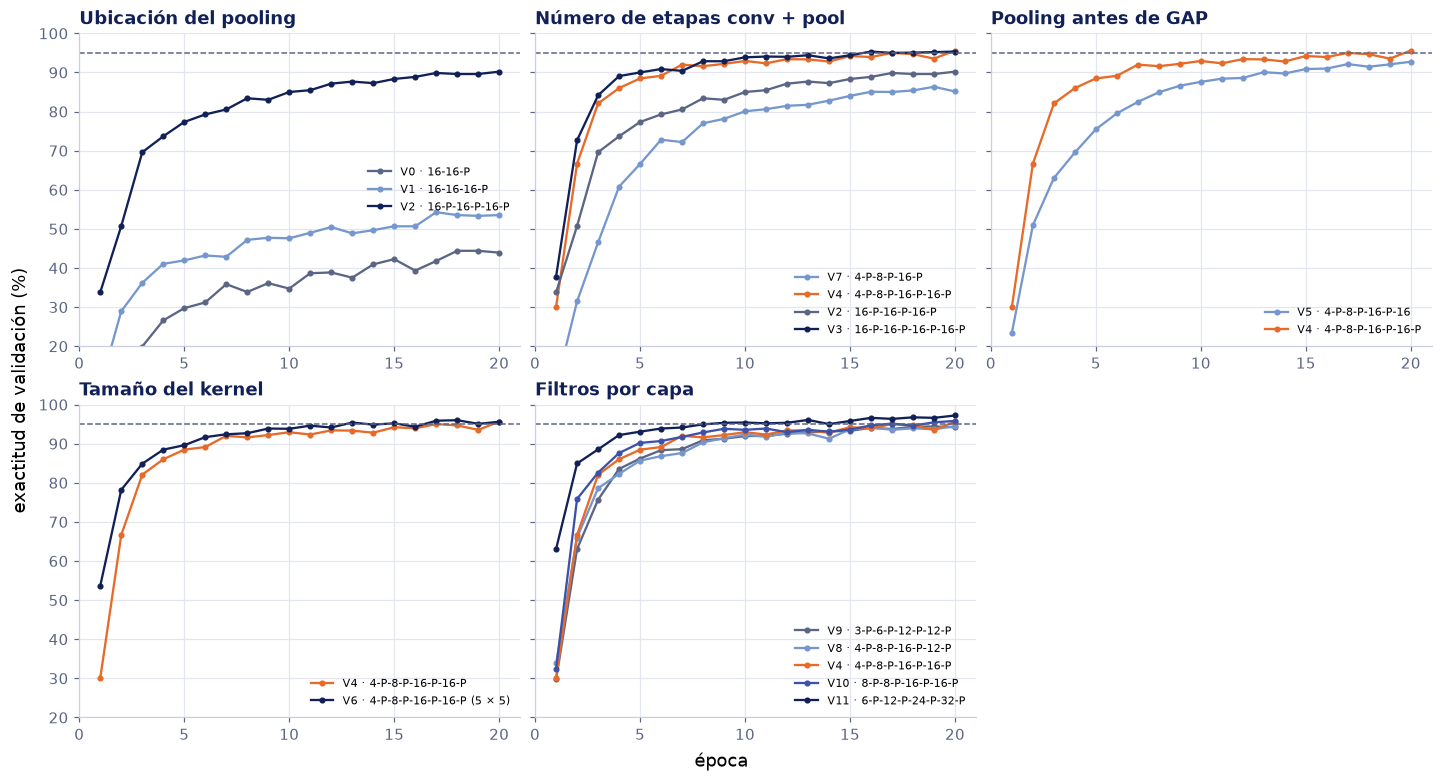

In [11]:
def curva(ax, clave, color, estilo="-"):
    valores = 100 * np.array(historiales_gap[clave]["val_accuracy"])
    etiqueta = f"{clave} · {tabla_val.loc[clave, 'Arquitectura']}"
    ax.plot(range(1, EPOCAS + 1), valores, estilo, marker="o", markersize=3,
            color=color, label=etiqueta)


PANELES = [
    ("Ubicación del pooling", [("V0", GRIS), ("V1", AZUL), ("V2", AZUL_OSCURO)]),
    ("Número de etapas conv + pool", [("V7", AZUL), ("V4", NARANJA), ("V2", GRIS), ("V3", AZUL_OSCURO)]),
    ("Pooling antes de GAP", [("V5", AZUL), ("V4", NARANJA)]),
    ("Tamaño del kernel", [("V4", NARANJA), ("V6", AZUL_OSCURO)]),
    ("Filtros por capa", [("V9", GRIS), ("V8", AZUL), ("V4", NARANJA), ("V10", AZUL_MEDIO),
                          ("V11", AZUL_OSCURO)]),
]

fig, ejes = plt.subplots(2, 3, figsize=(13, 7), sharey=True, layout="constrained")
for ax, (titulo, series) in zip(ejes.flat, PANELES):
    for clave, color in series:
        curva(ax, clave, color)
    ax.axhline(95, color=GRIS, linestyle="--", linewidth=1)
    ax.set(title=titulo, xticks=range(0, EPOCAS + 1, 5), xlim=(0, EPOCAS + 1), ylim=(20, 100))
    ax.legend(fontsize=7.5, loc="center right" if titulo == "Ubicación del pooling" else "lower right")
ejes.flat[-1].axis("off")
fig.supxlabel("época")
fig.supylabel("exactitud de validación (%)")
plt.show()

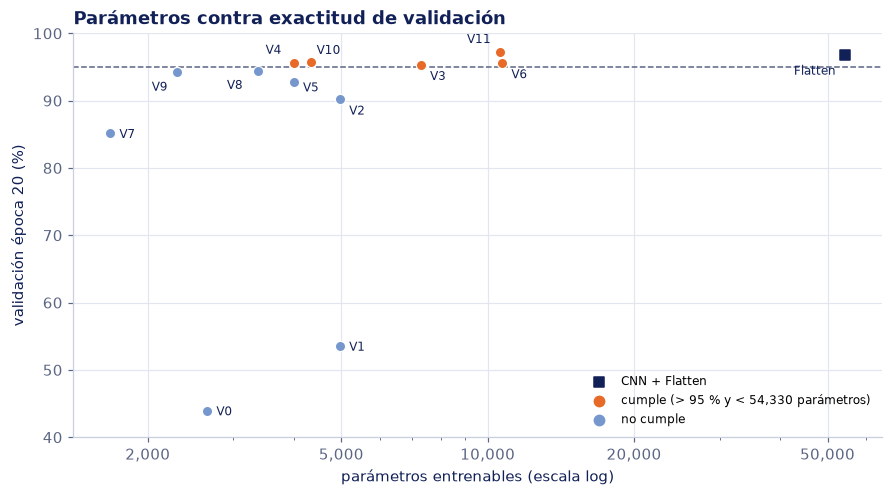

In [12]:
# Parámetros contra exactitud de validación de todas las variantes
DESFASE_ETIQUETA = {"V0": (6, -3), "V1": (6, -3), "V2": (6, -10), "V3": (6, -10), "V4": (-8, 6),
                    "V5": (6, -6), "V6": (6, -10), "V7": (6, -3), "V8": (-10, -12), "V9": (-6, -12),
                    "V10": (4, 5), "V11": (-6, 6)}

fig, ax = plt.subplots(figsize=(8, 4.4), layout="constrained")
for clave, fila in tabla_val.iterrows():
    color = NARANJA if fila["Cumple"] else AZUL
    ax.scatter(fila["Parámetros entrenables"], fila["Validación época 20 (%)"], s=45,
               color=color, edgecolor="white", linewidth=0.8, zorder=3)
    ax.annotate(clave, (fila["Parámetros entrenables"], fila["Validación época 20 (%)"]),
                xytext=DESFASE_ETIQUETA[clave], textcoords="offset points", fontsize=8,
                color=AZUL_OSCURO, ha="right" if DESFASE_ETIQUETA[clave][0] < 0 else "left")
ax.scatter(PARAMS_FLATTEN, 100 * hist_flatten["val_accuracy"][-1], marker="s", s=50,
           color=AZUL_OSCURO, zorder=3, label="CNN + Flatten")
ax.annotate("Flatten", (PARAMS_FLATTEN, 100 * hist_flatten["val_accuracy"][-1]),
            xytext=(-6, -13), textcoords="offset points", fontsize=8, color=AZUL_OSCURO, ha="right")
ax.scatter([], [], color=NARANJA, s=45, label="cumple (> 95 % y < 54,330 parámetros)")
ax.scatter([], [], color=AZUL, s=45, label="no cumple")
ax.axhline(95, color=GRIS, linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([2000, 5000, 10000, 20000, 50000])
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set(title="Parámetros contra exactitud de validación", xlabel="parámetros entrenables (escala log)",
       ylabel="validación época 20 (%)", ylim=(40, 100))
ax.legend(loc="lower right", fontsize=8)
plt.show()

### Lectura de las comparaciones

- **Ubicación del pooling (`V1` → `V2`).** Es el cambio con más efecto: **+36.67 pp** (de 53.53 % a 90.20 %) sin agregar un solo parámetro. Con el pooling al final, cada neurona ve 8 × 8 píxeles; al intercalarlo ve 22 × 22, suficiente para combinar varios trazos antes de que GAP los promedie. En las curvas, `V2` queda por encima de `V0` y `V1` desde la primera época.
- **Profundidad.** Agregar una convolución con el pooling al final apenas ayuda (+9.60 pp de `V0` a `V1`). Con el pooling intercalado, una cuarta etapa conv + pool sube +5.13 pp en la familia de 16 filtros (`V2` → `V3`) y +10.47 pp en la de 4-8-16 (`V7` → `V4`). Con cuatro etapas, el campo receptivo es de 46 píxeles, más grande que la imagen.
- **Pooling antes de GAP (`V5` → `V4`).** Con las mismas convoluciones y los mismos parámetros, agregar el último pooling sube +2.87 pp (de 92.73 % a 95.60 %). Sin él, GAP promedia 16 posiciones (4 × 4); con él, promedia 4 máximos locales (2 × 2), y el resultado se parece más a «¿apareció este patrón en algún lugar?» que a «¿cuánto espacio ocupa este patrón?».
- **Filtros.** Bajar las primeras capas de 16 a 4 y 8 filtros (`V3` → `V4`) quita 3,296 parámetros sin perder exactitud (de 95.33 % a 95.60 %). Las primeras capas detectan bordes y trazos simples y no necesitan muchos canales. En cambio, bajar la última capa de 16 a 12 filtros (`V8`) o estrechar todas las capas (`V9`) deja la red debajo del 95 %, porque los canales de la última capa son justamente los valores que recibe la capa de salida. Más filtros sí ayudan (`V11` llega a 97.20 %), pero cuestan 2.7 veces los parámetros de `V4`.
- **Kernel de 5 × 5 (`V4` → `V6`).** No cambia la exactitud (95.60 % en ambas) y multiplica los parámetros por 2.7 (de 3,994 a 10,714). Con cuatro poolings, el campo receptivo ya cubre la imagen, así que ampliarlo más no aporta.

En la gráfica de dispersión, las variantes que cumplen (en naranja) están entre 3,994 y 10,714 parámetros, todas muy por debajo de Flatten. Ninguna variante con menos parámetros que `V4` llega al 95 %.

### 2.4 Selección

Se filtran las variantes que cumplen ambos requisitos y se ordenan de menos a más parámetros. La primera es la seleccionada. Se usa el modelo ya entrenado, sin volver a entrenarlo.

In [13]:
candidatas = tabla_val[tabla_val["Cumple"]].sort_values("Parámetros entrenables")
CLAVE_SEL = candidatas.index[0]
modelo_sel = modelos_gap[CLAVE_SEL]
params_sel = int(candidatas.loc[CLAVE_SEL, "Parámetros entrenables"])
ahorro = PARAMS_FLATTEN - params_sel

display(candidatas[["Arquitectura", "Parámetros entrenables", "Validación época 20 (%)"]].round(2))
print(f"Seleccionada: {CLAVE_SEL} · {candidatas.loc[CLAVE_SEL, 'Arquitectura']}")
print(f"Validación:   {candidatas.loc[CLAVE_SEL, 'Validación época 20 (%)']:.2f} %")
print(f"Parámetros:   {params_sel:,} frente a {PARAMS_FLATTEN:,} de Flatten")
print(f"Ahorro:       {ahorro:,} parámetros ({100 * ahorro / PARAMS_FLATTEN:.1f} % menos; "
      f"Flatten es {PARAMS_FLATTEN / params_sel:.1f} veces más grande)")

,Arquitectura,Parámetros entrenables,Validación época 20 (%)
Variante,,,
V4,4-P-8-P-16-P-16-P,3994,95.60
V10,8-P-8-P-16-P-16-P,4322,95.80
V3,16-P-16-P-16-P-16-P,7290,95.33
V11,6-P-12-P-24-P-32-P,10610,97.20
V6,4-P-8-P-16-P-16-P (5 × 5),10714,95.60


Seleccionada: V4 · 4-P-8-P-16-P-16-P
Validación:   95.60 %
Parámetros:   3,994 frente a 54,330 de Flatten
Ahorro:       50,336 parámetros (92.6 % menos; Flatten es 13.6 veces más grande)


In [14]:
pd.DataFrame([
    {"Capa": capa.name, "Tipo": type(capa).__name__,
     "Salida": " × ".join(map(str, capa.output.shape[1:])), "Parámetros": capa.count_params()}
    for capa in modelo_sel.layers
]).set_index("Capa")

,Tipo,Salida,Parámetros
Capa,,,
conv_1,Conv2D,36 × 36 × 4,40
pool_1,MaxPooling2D,18 × 18 × 4,0
conv_2,Conv2D,18 × 18 × 8,296
pool_2,MaxPooling2D,9 × 9 × 8,0
conv_3,Conv2D,9 × 9 × 16,1168
pool_3,MaxPooling2D,4 × 4 × 16,0
conv_4,Conv2D,4 × 4 × 16,2320
pool_4,MaxPooling2D,2 × 2 × 16,0
vector,GlobalAveragePooling2D,16,0


**Respuesta.** Cinco variantes cumplen los dos requisitos, y la de menos parámetros es **`V4 · 4-P-8-P-16-P-16-P`**, con **95.60 %** de exactitud en validación y **3,994 parámetros entrenables**. Frente a los 54,330 de Flatten, ahorra **50,336 parámetros (92.6 % menos)**; Flatten es 13.6 veces más grande.

En `V4`, la capa de salida tiene solo 170 pesos y la mayor parte del modelo está en la última convolución (2,320). En Flatten pasa lo contrario: el extractor tiene 2,480 parámetros y la capa densa 51,850.

Respecto al GAP base, estos son los cambios que llevaron la exactitud de 43.93 % a 95.60 %, en orden de importancia:

1. **Intercalar el pooling** entre las convoluciones. Por sí solo vale +36.67 pp con los mismos parámetros.
2. **Agregar una cuarta etapa conv + pool**, para que el campo receptivo cubra el dígito completo (46 px) y el mapa llegue a GAP con tamaño 2 × 2.
3. **Repartir los filtros de forma creciente** (4 → 8 → 16 → 16): pocos canales al inicio, donde los mapas son grandes y cada filtro cuesta más operaciones, y 16 al final, que son los valores que lee la capa de salida.

`V4` cumple con poco margen: 95.60 % frente al umbral de 95 %, unas 9 imágenes de validación. `V10` y `V11` tienen más margen (95.80 % y 97.20 %), pero la regla de la tarea es quedarse con la de menos parámetros, y la decisión se tomó solo con validación.

---

## 3. Efecto del desplazamiento

**Pregunta / Punto.** Compara Flatten base, GAP base y el GAP seleccionado sobre las mismas imágenes de prueba con la función `desplazar` del notebook, a 0, 2 y 4 píxeles y sin reentrenar. Para 2 y 4 píxeles, promedia la exactitud hacia arriba, abajo, izquierda y derecha. Reporta la caída como Acc(0 px) − Acc(4 px).

Aquí se usa el conjunto de prueba por primera vez. Los tres modelos ya están entrenados y no se modifican: solo se mueven las imágenes de entrada. `desplazar` copia cada dígito corrido `dy` píxeles en vertical y `dx` en horizontal y rellena con negro lo que queda vacío. Como el margen es de 4 píxeles, el trazo nunca se recorta.

Además de la caída, la tabla muestra qué fracción de su exactitud a 0 px conserva cada modelo a 4 px. Un modelo puede caer poco porque nunca clasificó bien, y por eso se revisan las dos cosas.

In [15]:
def desplazar(imagenes, dy, dx):
    """Función del notebook de clase: mueve el lote dy píxeles en vertical y dx en horizontal."""
    if max(abs(dy), abs(dx)) > MARGEN:
        raise ValueError("Usa un desplazamiento dentro del margen de la imagen.")
    alto, ancho = imagenes.shape[1:3]
    resultado = np.zeros_like(imagenes)
    origen_y = slice(max(-dy, 0), alto - max(dy, 0))
    origen_x = slice(max(-dx, 0), ancho - max(dx, 0))
    destino_y = slice(max(dy, 0), alto - max(-dy, 0))
    destino_x = slice(max(dx, 0), ancho - max(-dx, 0))
    resultado[:, destino_y, destino_x, :] = imagenes[:, origen_y, origen_x, :]
    return resultado


def predecir(modelo, imagenes):
    return modelo.predict(lotes(imagenes), verbose=0).argmax(axis=1)


NOMBRE_SEL = f"GAP seleccionado ({CLAVE_SEL})"
modelos = {"CNN + Flatten": modelo_flatten, "CNN + GAP base": modelo_gap_base, NOMBRE_SEL: modelo_sel}
distancias = (0, 2, 4)
DIRECCIONES = {"derecha": (0, 1), "izquierda": (0, -1), "abajo": (1, 0), "arriba": (-1, 0)}

pred_originales = {nombre: predecir(m, X_prueba) for nombre, m in modelos.items()}
exactitudes = {nombre: [100 * np.mean(p == y_prueba)] for nombre, p in pred_originales.items()}
por_direccion, pred_derecha = [], {}
for d in distancias[1:]:
    acumulado = {nombre: [] for nombre in modelos}
    for direccion, (uy, ux) in DIRECCIONES.items():
        imagenes = desplazar(X_prueba, uy * d, ux * d)
        for nombre, m in modelos.items():
            pred = predecir(m, imagenes)
            acc = 100 * np.mean(pred == y_prueba)
            acumulado[nombre].append(acc)
            por_direccion.append({"Modelo": nombre, "Distancia": f"{d} px", "Dirección": direccion,
                                  "Exactitud (%)": acc})
            if direccion == "derecha" and d == MARGEN:
                pred_derecha[nombre] = pred
    for nombre, valores in acumulado.items():
        exactitudes[nombre].append(float(np.mean(valores)))

tabla_desp = pd.DataFrame.from_dict(exactitudes, orient="index",
                                    columns=[f"{d} px (%)" for d in distancias])
tabla_desp.insert(0, "Parámetros", [parametros(m) for m in modelos.values()])
tabla_desp["Caída 0 → 4 px (pp)"] = tabla_desp["0 px (%)"] - tabla_desp["4 px (%)"]
tabla_desp["Conserva a 4 px (% de 0 px)"] = 100 * tabla_desp["4 px (%)"] / tabla_desp["0 px (%)"]
tabla_desp.index.name = "Modelo"
tabla_desp.round(2)

,Parámetros,0 px (%),2 px (%),4 px (%),Caída 0 → 4 px (pp),Conserva a 4 px (% de 0 px)
Modelo,,,,,,
CNN + Flatten,54330,97.10,82.80,37.30,59.80,38.41
CNN + GAP base,2650,46.25,46.25,46.25,0.00,100.00
GAP seleccionado (V4),3994,94.90,87.85,63.25,31.65,66.65


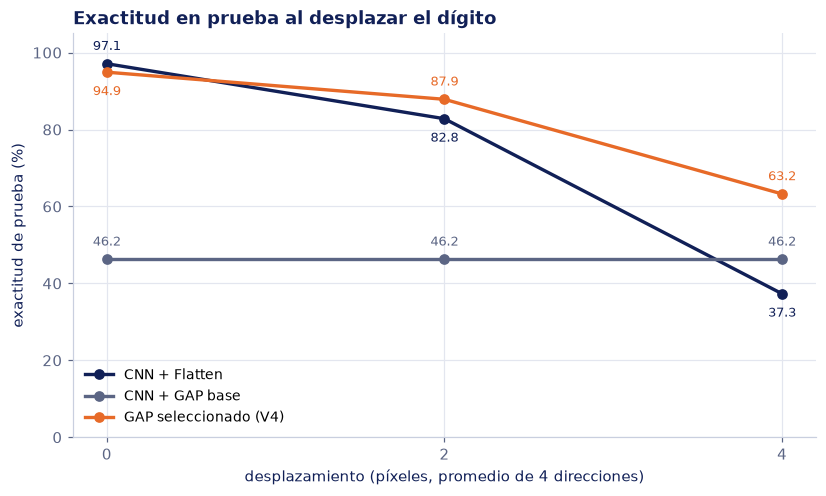

Distancia               2 px                            4 px                         
Dirección              abajo arriba derecha izquierda  abajo arriba derecha izquierda
Modelo                                                                               
CNN + Flatten          83.20  79.95   86.50     81.55  28.05  27.20   48.80     45.15
CNN + GAP base         46.25  46.25   46.25     46.25  46.25  46.25   46.25     46.25
GAP seleccionado (V4)  87.15  82.05   90.40     91.80  59.70  43.90   68.65     80.75

In [16]:
COLORES = {"CNN + Flatten": AZUL_OSCURO, "CNN + GAP base": GRIS, NOMBRE_SEL: NARANJA}
# La etiqueta va arriba (+1) o abajo (-1) del punto, según la distancia, para que no se encimen
LADO = {"CNN + Flatten": (1, -1, -1), "CNN + GAP base": (1, 1, 1), NOMBRE_SEL: (-1, 1, 1)}

fig, ax = plt.subplots(figsize=(7.4, 4.4), layout="constrained")
for nombre, valores in exactitudes.items():
    ax.plot(distancias, valores, marker="o", linewidth=2.2, color=COLORES[nombre], label=nombre)
    for d, v, lado in zip(distancias, valores, LADO[nombre]):
        ax.annotate(f"{v:.1f}", (d, v), xytext=(0, 9 if lado > 0 else -15), textcoords="offset points",
                    ha="center", fontsize=8.5, color=COLORES[nombre])
ax.set(title="Exactitud en prueba al desplazar el dígito",
       xlabel="desplazamiento (píxeles, promedio de 4 direcciones)",
       ylabel="exactitud de prueba (%)", xticks=distancias, ylim=(0, 105))
ax.legend(loc="lower left", fontsize=9)
plt.show()

(pd.DataFrame(por_direccion)
   .pivot_table(index="Modelo", columns=["Distancia", "Dirección"], values="Exactitud (%)")
   .reindex(modelos).round(2))

**Respuesta.**

- **CNN + Flatten** es la mejor con los dígitos centrados (97.10 %), pero baja a 82.80 % a 2 px y a 37.30 % a 4 px. Cae **59.80 pp** y conserva solo el 38 % de su exactitud. Cada peso de su capa densa está atado a una posición del mapa de 18 × 18, así que al mover el dígito las activaciones caen sobre pesos que aprendieron otra cosa.
- **CNN + GAP base** no cambia nada: 46.25 % en las tres distancias y una caída de 0.00 pp. La invariancia es exacta por una razón concreta. Su único pooling tiene paso 2, y 2 y 4 píxeles son múltiplos de ese paso, así que el mapa que llega a GAP es el mismo mapa trasladado y su promedio no cambia. Aun así, no perder exactitud sirve de poco si el modelo parte de 46 %.
- **GAP seleccionado (`V4`)** empieza 2.2 pp debajo de Flatten (94.90 % contra 97.10 %), pero a 2 px ya lo supera (87.85 % contra 82.80 %) y a 4 px conserva **63.25 %**: 25.95 pp más que Flatten y 17.00 pp más que el GAP base. Cae 31.65 pp, poco más de la mitad que Flatten, y conserva dos tercios de su exactitud.

`V4` tampoco es invariante al desplazamiento. Sus cuatro poolings acumulan un paso de 16 píxeles, y 2 o 4 px no son múltiplos de 16. Al mover el dígito cambia qué valores caen en cada ventana de pooling, y el mapa final de 2 × 2 ya no es una simple traslación del original (Zhang, 2019; Azulay y Weiss, 2019). Por eso su pérdida depende de la dirección: a 4 px conserva 80.75 % hacia la izquierda, pero solo 43.90 % hacia arriba. GAP quita la dependencia de la posición en la capa de salida, pero el submuestreo del extractor sigue haciendo a la red sensible a la posición.

Casos así en prueba: 570 de 2000


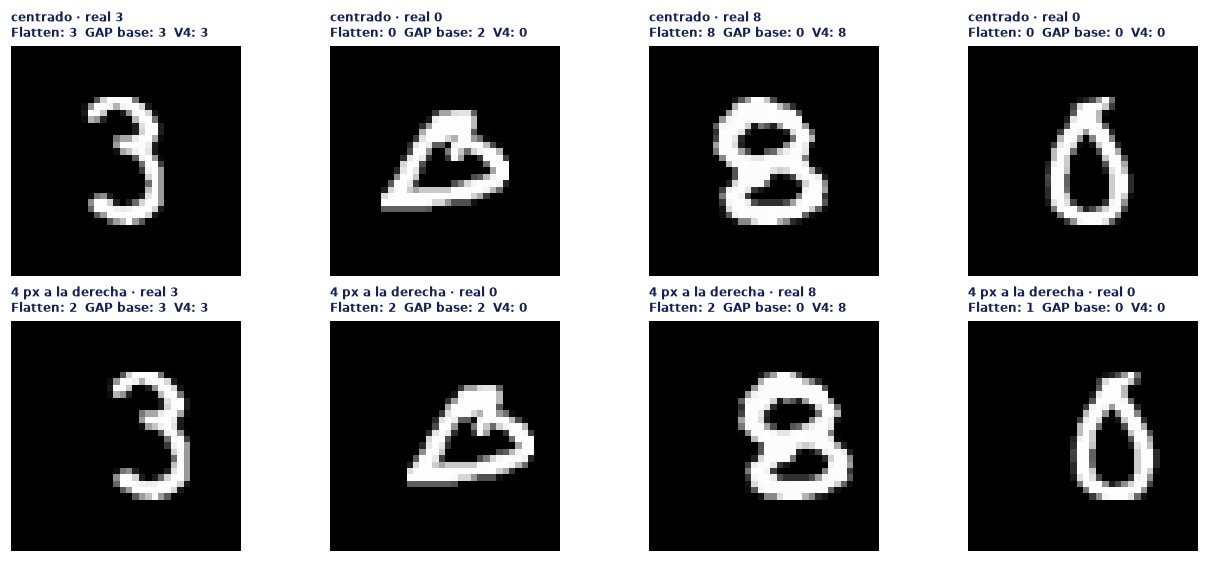

In [17]:
# Dígitos que Flatten acierta centrados, falla a 4 px a la derecha y el GAP seleccionado conserva
casos = np.flatnonzero(
    (pred_originales["CNN + Flatten"] == y_prueba)
    & (pred_derecha["CNN + Flatten"] != y_prueba)
    & (pred_derecha[NOMBRE_SEL] == y_prueba)
)[:4]
print(f"Casos así en prueba: "
      f"{np.sum((pred_originales['CNN + Flatten'] == y_prueba) & (pred_derecha['CNN + Flatten'] != y_prueba) & (pred_derecha[NOMBRE_SEL] == y_prueba))} de {len(y_prueba)}")

cortos = {"CNN + Flatten": "Flatten", "CNN + GAP base": "GAP base", NOMBRE_SEL: CLAVE_SEL}
fig, ejes = plt.subplots(2, len(casos), figsize=(2.9 * len(casos), 5), squeeze=False,
                         layout="constrained")
for col, i in enumerate(casos):
    imagenes = (X_prueba[i, ..., 0], desplazar(X_prueba[i:i + 1], 0, MARGEN)[0, ..., 0])
    for fila, (etiqueta, pred) in enumerate([("centrado", pred_originales),
                                             ("4 px a la derecha", pred_derecha)]):
        ax = ejes[fila, col]
        ax.imshow(imagenes[fila], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{etiqueta} · real {y_prueba[i]}\n"
                     + "  ".join(f"{cortos[n]}: {pred[n][i]}" for n in modelos), fontsize=8)
        ax.axis("off")
plt.show()

En prueba, 570 de los 2,000 dígitos cumplen esta condición: Flatten los reconoce centrados, falla al moverlos 4 píxeles a la derecha y `V4` sigue acertando. En los cuatro ejemplos el dígito es igual de legible después del desplazamiento, pero Flatten cambia su respuesta (en tres de ellos responde 2). El GAP base no depende de la posición, pero se equivoca con el 0 inclinado y con el 8 incluso sin moverlos.

---

## Conclusión

**¿Cuál fue el cambio más importante para que GAP superara el 95 % en validación?**
Intercalar el *max pooling* entre las convoluciones en lugar de dejarlo solo al final. Con las mismas tres convoluciones y los mismos 4,970 parámetros, la exactitud de validación pasó de 53.53 % (`V1`) a 90.20 % (`V2`). El pooling no tiene pesos, pero cada uno duplica el paso de las convoluciones siguientes, y el campo receptivo creció de 8 a 22 píxeles. Así, cada canal ve formas completas del dígito antes de que GAP lo promedie. Sobre esa base, una cuarta etapa conv + pool (campo receptivo de 46 px), con el último pooling justo antes de GAP, llevó la red por encima del 95 %.

**¿Cuántos parámetros ahorraste frente a Flatten?**
El GAP seleccionado, `V4 · 4-P-8-P-16-P-16-P`, tiene 3,994 parámetros entrenables frente a los 54,330 de Flatten: **50,336 parámetros menos (92.6 %)**, con 95.60 % de exactitud en validación. Casi todo el ahorro viene de la capa de salida, que pasa de 51,850 a 170 pesos. El resto viene de usar solo 4 y 8 filtros en las dos primeras capas.

**¿Tu GAP seleccionado reconoce mejor los dígitos desplazados que Flatten? ¿A partir de qué distancia se aprecia la diferencia?**
Sí. Con los dígitos centrados, Flatten es mejor (97.10 % contra 94.90 %), pero desde **2 píxeles** el orden se invierte: `V4` obtiene 87.85 % y Flatten 82.80 %. A 4 píxeles la diferencia crece a 25.95 pp (63.25 % contra 37.30 %). `V4` cae 31.65 pp y conserva dos tercios de su exactitud; Flatten cae 59.80 pp y conserva poco más de un tercio. El GAP base no cae nada, pero se queda en 46.25 % en todas las distancias: una caída pequeña solo es útil cuando la exactitud de partida es alta.

En prueba, `V4` quedó en 94.90 %, debajo del 95.60 % que obtuvo en validación. La selección se hizo solo con validación, como pide la tarea, y con un margen de 0.6 pp una diferencia así es esperable con 1,500 y 2,000 imágenes. Si se quisiera más margen, `V11` (10,610 parámetros y 97.20 % en validación) seguiría usando menos de una quinta parte de los parámetros de Flatten.

---

## Declaración de uso de IA generativa

Este notebook utilizó Claude (Anthropic) como asistente para estructurar el notebook (Markdown), redactar y revisar los textos, así como la depuración de código.

## Referencias

- LeCun, Y., Bottou, L., Bengio, Y., & Haffner, P. (1998). Gradient-based learning applied to document recognition. *Proceedings of the IEEE*, 86(11), 2278-2324.
- Lin, M., Chen, Q., & Yan, S. (2014). Network in network. *International Conference on Learning Representations (ICLR)*. https://arxiv.org/abs/1312.4400
- Zhang, R. (2019). Making convolutional networks shift-invariant again. *Proceedings of the 36th International Conference on Machine Learning (ICML)*, 7324-7334.
- Azulay, A., & Weiss, Y. (2019). Why do deep convolutional networks generalize so poorly to small image transformations? *Journal of Machine Learning Research*, 20(184), 1-25.
- [Keras: Conv2D](https://keras.io/api/layers/convolution_layers/convolution2d/) · [MaxPooling2D](https://keras.io/api/layers/pooling_layers/max_pooling2d/) · [GlobalAveragePooling2D](https://keras.io/api/layers/pooling_layers/global_average_pooling2d/)